In [1]:
# ==== S4a: CAMERA FEATURES FOR EVERY FRAME + AUGMENTED COPIES OF THE TRAINING FRAMES (run on your PC, after S2)
# needs: torch, torchvision, pillow, numpy, pandas. CPU: about 10-20 minutes for Sc32.
"""
For every S1 frame: ResNet18 (ImageNet) on the full image, resized to 224 high keeping the aspect ratio; the last
feature map (512 x 7 rows x 12 columns) is averaged over the ROWS only -> (512, 12). Keeping the 12 columns keeps
WHERE things are left-right in the image, which decides the beam.
Augmentation (training drives only, N_AUG copies per frame), LABEL-SAFE only:
  brightness / contrast / saturation, slight blur, sensor noise, small VERTICAL shift.
  NOT used: horizontal flip or horizontal shift / crop. On Sc32, beam ~ -2.0 + 61.8 * x_image, so a 5 % horizontal
  shift moves the true beam by about 3 beams, and a flip with beam -> 63 - beam is wrong by about 5 beams.
Output S<scen>/S4_cam_feats.npy  float16 (1 + N_AUG, frames, 512, 12): version 0 = original image,
       versions 1.. = augmented (equal to the original for validation / test frames, which are never augmented)
"""
import os, sys, time, argparse
import numpy as np
import pandas as pd
import torch, torchvision
from PIL import Image, ImageEnhance, ImageFilter

ap = argparse.ArgumentParser()
ap.add_argument("--work", default=r"C:\Users\abdel\OneDrive\Desktop\ODT", help="folder with scenarioXX and SXX")
ap.add_argument("--scen", default="32")
ap.add_argument("--n_aug", type=int, default=2)
ap.add_argument("--seed", type=int, default=0)
ap.add_argument("--random_weights", action="store_true", help="only to test the code without downloading weights")
A = ap.parse_args([])   # notebook: settings are the defaults above
if os.path.isdir(A.work):
    os.chdir(A.work)
print("working folder:", os.getcwd())
D, SD = f"S{A.scen}", f"scenario{A.scen}"
df = pd.read_csv(os.path.join(D, f"S{A.scen}_frames.csv"))
N = len(df); rng = np.random.default_rng(A.seed)


def fpath(p):
    p = str(p).strip()
    return os.path.join(SD, p[2:] if p.startswith("./") else p)


def augment(im):
    """label-safe: photometric changes, blur, noise, vertical shift (never horizontal)"""
    im = ImageEnhance.Brightness(im).enhance(rng.uniform(0.6, 1.4))
    im = ImageEnhance.Contrast(im).enhance(rng.uniform(0.7, 1.3))
    im = ImageEnhance.Color(im).enhance(rng.uniform(0.7, 1.3))
    if rng.random() < 0.3:
        im = im.filter(ImageFilter.GaussianBlur(rng.uniform(0.3, 1.2)))
    a = np.asarray(im).astype(np.float32)
    dy = int(rng.integers(-int(0.05 * a.shape[0]), int(0.05 * a.shape[0]) + 1))
    a = np.roll(a, dy, axis=0)
    if dy > 0:
        a[:dy] = a[dy:dy + 1]
    elif dy < 0:
        a[dy:] = a[dy - 1:dy]
    a += rng.normal(0, rng.uniform(0, 8), a.shape)
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))


dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = torchvision.models.resnet18(weights=None if A.random_weights else torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
body = torch.nn.Sequential(*list(net.children())[:-2]).to(dev).eval()
mean = torch.tensor([0.485, 0.456, 0.406], device=dev)[:, None, None]; std = torch.tensor([0.229, 0.224, 0.225], device=dev)[:, None, None]
im0 = Image.open(fpath(df["img_path"][0])).convert("RGB")
W_IN = int(round(224 * im0.size[0] / im0.size[1] / 32)) * 32
print(f"device {dev} | image {im0.size} -> {W_IN}x224 | {A.n_aug} augmented copies of each training frame")

V = 1 + A.n_aug
F = None
train = (df["split"] == "train").to_numpy()
jobs = [(0, i) for i in range(N)] + [(v, i) for v in range(1, V) for i in range(N) if train[i]]
t0 = time.time()
with torch.no_grad():
    for b0 in range(0, len(jobs), 32):
        batch, where = [], []
        for v, i in jobs[b0:b0 + 32]:
            try:
                im = Image.open(fpath(df["img_path"][i])).convert("RGB")
            except OSError:
                continue
            if v > 0:
                im = augment(im)
            batch.append(torch.from_numpy(np.array(im.resize((W_IN, 224), Image.BILINEAR))).permute(2, 0, 1)); where.append((v, i))
        if not batch:
            continue
        f = body(((torch.stack(batch).to(dev).float() / 255) - mean) / std).mean(2).cpu().numpy().astype(np.float16)
        if F is None:
            F = np.zeros((V, N) + f.shape[1:], np.float16)
        for (v, i), fi in zip(where, f):
            F[v, i] = fi
        if b0 % 1600 == 0:
            print(f"  {min(b0 + 32, len(jobs))}/{len(jobs)} images ({time.time() - t0:.0f} s)")
for v in range(1, V):                                        # validation / test frames: copy the original (never augmented)
    F[v, ~train] = F[0, ~train]
missing = int(np.sum(np.abs(F[0].astype(np.float32)).sum((1, 2)) == 0))
np.save(os.path.join(D, "S4_cam_feats.npy"), F)
print(f"saved {D}/S4_cam_feats.npy  shape {F.shape} ({F.nbytes / 1e6:.0f} MB) | frames without an image: {missing} | "
      f"{(time.time() - t0) / 60:.1f} min")
d = np.abs(F[1, train].astype(np.float32) - F[0, train].astype(np.float32)).mean() / (np.abs(F[0, train].astype(np.float32)).mean() + 1e-9)
print(f"check: augmented copies differ from the originals by {100 * d:.0f} % on average (should be clearly above 0)")

working folder: C:\Users\abdel\OneDrive\Desktop\ODT
device cpu | image (960, 540) -> 384x224 | 2 augmented copies of each training frame
  32/7249 images (1 s)
  1632/7249 images (75 s)
  3232/7249 images (148 s)
  4832/7249 images (265 s)
  6432/7249 images (373 s)
saved S32/S4_cam_feats.npy  shape (3, 3235, 512, 12) (119 MB) | frames without an image: 0 | 7.1 min
check: augmented copies differ from the originals by 33 % on average (should be clearly above 0)


Object Detection


In [6]:
# ==== S5a: VEHICLE DETECTION ON EVERY FRAME (YOLOv8n, pretrained on COCO) - run on your PC after S1
# needs: ultralytics (pip install ultralytics), numpy, pandas. CPU: about 5-10 minutes for Sc32.
"""
For every S1 frame: all detected vehicles (car, motorcycle, bus, truck), the MAX_BOX most confident ones.
Output S<scen>/S5_yolo.npy  float32 (frames, MAX_BOX, 6) = x-centre, y-centre, width, height (0..1 of the image),
       confidence, COCO class; empty slots are 0.  + S5a_report.txt
No GPS here and nothing chooses "the" car: S5b labels the target (training drives), S5c learns to find it.
"""
import os, sys, time, argparse
import numpy as np
import pandas as pd

ap = argparse.ArgumentParser()
ap.add_argument("--work", default=r"C:\Users\abdel\OneDrive\Desktop\ODT")
ap.add_argument("--scen", default="32")
ap.add_argument("--max_box", type=int, default=8)
ap.add_argument("--conf", type=float, default=0.25, help="YOLO confidence threshold")
A = ap.parse_args([])   # notebook: settings are the defaults above
if os.path.isdir(A.work):
    os.chdir(A.work)
D, SD = f"S{A.scen}", f"scenario{A.scen}"


class Tee:
    def __init__(self, path):
        self.f, self.o = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.o.write(s); self.f.write(s); self.f.flush()

    def flush(self):
        self.o.flush(); self.f.flush()


while hasattr(sys.stdout, "o"):
    sys.stdout = sys.stdout.o
sys.stdout = Tee(os.path.join(D, "S5a_report.txt"))

from ultralytics import YOLO
import torch
df = pd.read_csv(os.path.join(D, f"S{A.scen}_frames.csv"))
N = len(df)
paths = [os.path.join(SD, p[2:] if str(p).startswith("./") else str(p)) for p in df["img_path"]]
det = YOLO("yolov8n.pt"); VEH = {2, 3, 5, 7}                                  # COCO: car, motorcycle, bus, truck
device = 0 if torch.cuda.is_available() else "cpu"
Y = np.zeros((N, A.max_box, 6), np.float32)
t0 = time.time()
for i0 in range(0, N, 32):
    for j, r in enumerate(det(paths[i0:i0 + 32], verbose=False, device=device, conf=A.conf)):
        b = r.boxes
        keep = sorted([k for k in range(len(b)) if int(b.cls[k]) in VEH], key=lambda k: -float(b.conf[k]))[:A.max_box]
        for s, k in enumerate(keep):
            Y[i0 + j, s, :4] = b.xywhn[k].cpu().numpy(); Y[i0 + j, s, 4] = float(b.conf[k]); Y[i0 + j, s, 5] = int(b.cls[k])
    if i0 % 640 == 0:
        print(f"  {min(i0 + 32, N)}/{N} frames ({time.time() - t0:.0f} s)")
np.save(os.path.join(D, "S5_yolo.npy"), Y)
nb = (Y[:, :, 4] > 0).sum(1)
print(f"\nvehicles per frame: none {100 * np.mean(nb == 0):.1f} % | one {100 * np.mean(nb == 1):.1f} % | "
      f"two or more {100 * np.mean(nb >= 2):.1f} % | mean {nb.mean():.1f} | max {nb.max()} "
      f"(frames at the {A.max_box}-box limit: {100 * np.mean(nb == A.max_box):.1f} %)")
print(f"saved {D}/S5_yolo.npy {Y.shape} | {(time.time() - t0) / 60:.1f} min")

while hasattr(sys.stdout, "o"):        # back to normal printing
    sys.stdout = sys.stdout.o

Target Labels

[1] frames 3235 | used to fit (training drives, usable, non-interpolated GPS) 1795 | boxes per frame 4.8
[2] parked boxes (same place in >= 80 % of their drive): 26.1 % of boxes
    iteration 1: x = 0.298 + +0.0061 * bearing | height = 1.64 / distance | picks changed 975
    iteration 2: x = 0.227 + +0.0073 * bearing | height = 1.61 / distance | picks changed 238
    iteration 3: x = 0.207 + +0.0076 * bearing | height = 1.57 / distance | picks changed 115
    iteration 4: x = 0.189 + +0.0077 * bearing | height = 1.54 / distance | picks changed 152
    iteration 5: x = 0.176 + +0.0078 * bearing | height = 1.51 / distance | picks changed 132
    iteration 6: x = 0.120 + +0.0087 * bearing | height = 1.49 / distance | picks changed 405
    iteration 7: x = 0.071 + +0.0095 * bearing | height = 1.49 / distance | picks changed 246
    iteration 8: x = 0.068 + +0.0095 * bearing | height = 1.49 / distance | picks changed 43
    iteration 9: x = 0.066 + +0.0096 * bearing | height = 1.50 / distan

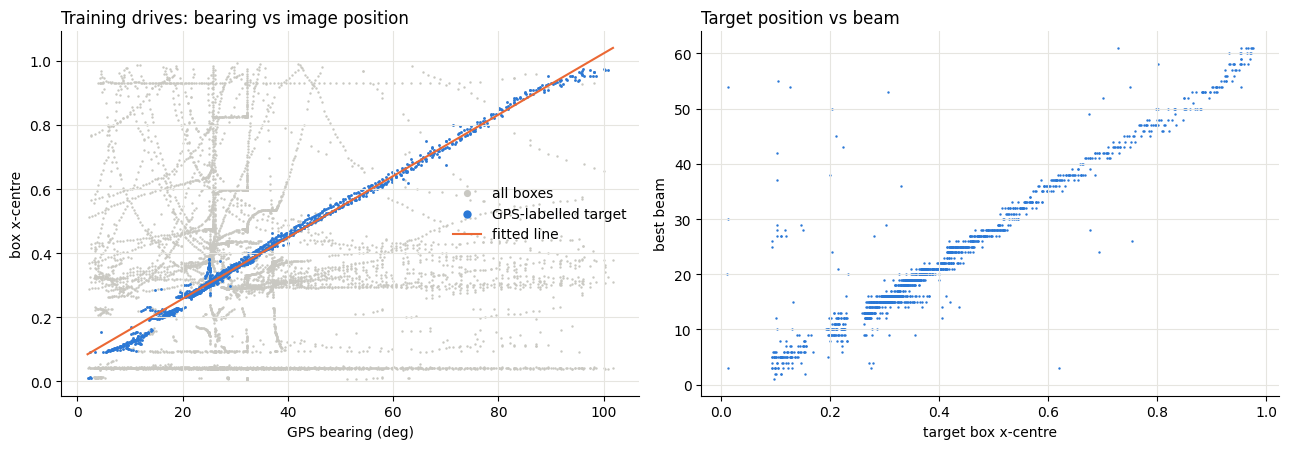


saved S32/S5_target.npz, S5b_report.txt, S5b_bearing_vs_x.png


In [7]:
# ==== S5b: WHICH BOX IS THE TEST CAR? GPS LABELS, FITTED ON THE TRAINING DRIVES ONLY (run after S5a)
# needs: numpy, pandas, matplotlib. Seconds.
"""
The camera is fixed, so a car at GPS bearing g appears near image position  x = a + b * g, and closer cars look
bigger: box height ~ c / distance. a, b, c are fitted robustly on the TRAINING drives only (non-interpolated GPS),
starting from "largest box", then every frame re-picks the box with the lowest
    cost = |x - x_pred| + LAM * |log h - log(c / distance)|,  repeated until the picks stop changing.
Parked cars (a box at the same place in >= STATIC of its drive) are never the target.
target_found = best box within X_TOL of the line. Validation / test frames are labelled with the fitted line only
to MEASURE target finding there; nothing is trained on them. GPS is never a model input.
Output S<scen>/S5_target.npz (per frame: target_idx, target_found, parked), S5b_report.txt, S5b_bearing_vs_x.png
"""
import os, sys, argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ap = argparse.ArgumentParser()
ap.add_argument("--work", default=r"C:\Users\abdel\OneDrive\Desktop\ODT")
ap.add_argument("--scen", default="32")
ap.add_argument("--lam", type=float, default=0.1)
ap.add_argument("--x_tol", type=float, default=0.08)
ap.add_argument("--static", type=float, default=0.8)
ap.add_argument("--iters", type=int, default=20)
A = ap.parse_args([])   # notebook: settings are the defaults above
if os.path.isdir(A.work):
    os.chdir(A.work)
D = f"S{A.scen}"


class Tee:
    def __init__(self, path):
        self.f, self.o = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.o.write(s); self.f.write(s); self.f.flush()

    def flush(self):
        self.o.flush(); self.f.flush()


while hasattr(sys.stdout, "o"):
    sys.stdout = sys.stdout.o
sys.stdout = Tee(os.path.join(D, "S5b_report.txt"))

# ------------------------------------------------------------------ 1. load
df = pd.read_csv(os.path.join(D, f"S{A.scen}_frames.csv"))
Yb = np.load(os.path.join(D, "S5_yolo.npy"))
N, K, _ = Yb.shape
X, Yc, W, H, C = (Yb[:, :, j] for j in range(5))
real = C > 0
seq, beam = df["seq"].to_numpy(), df["beam"].to_numpy()
g, dist = df["bearing_deg"].to_numpy(), df["dist_m"].to_numpy()
gps_ok = np.isfinite(g) & np.isfinite(dist) & ~df["gps_interp"].astype(bool).to_numpy()
use = df["usable"].to_numpy() & gps_ok
fit = use & (df["split"] == "train").to_numpy()
print(f"[1] frames {N} | used to fit (training drives, usable, non-interpolated GPS) {fit.sum()} | boxes per frame {real.sum(1).mean():.1f}")

# ------------------------------------------------------------------ 2. parked cars
stat = np.zeros((N, K))
for s_ in np.unique(seq):
    ix = np.flatnonzero(seq == s_)
    bx, by, br = X[ix], Yc[ix], real[ix]
    for k in range(K):
        same = (np.abs(bx[:, k][:, None, None] - bx[None]) < 0.015) & (np.abs(by[:, k][:, None, None] - by[None]) < 0.03) & br[None]
        stat[ix, k] = same.any(2).mean(1)
parked = real & (stat >= A.static)
cand = real & ~parked
print(f"[2] parked boxes (same place in >= {100 * A.static:.0f} % of their drive): {100 * parked.sum() / max(real.sum(), 1):.1f} % of boxes")

# ------------------------------------------------------------------ 3. fit line + size, re-pick until stable
rows = np.arange(N)


def amin(cost, m):
    c = np.where(m, cost, np.inf); i = c.argmin(1)
    return np.where(np.isfinite(c.min(1)), i, -1)


def robust_line(gx, x, keep=0.7, iters=4):
    m = np.ones(len(gx), bool)
    for _ in range(iters):
        b, a = np.polyfit(gx[m], x[m], 1); r = np.abs(x - (a + b * gx)); m = r <= np.quantile(r, keep)
    return a, b


pick = amin(-(W * H), cand)
for it in range(A.iters):
    ok = fit & (pick >= 0)
    a, b = robust_line(g[ok], X[rows[ok], pick[ok]])
    xp = a + b * np.nan_to_num(g)
    near = ok & (np.abs(X[rows, np.maximum(pick, 0)] - xp) < A.x_tol)
    c = np.median(H[rows[near], pick[near]] * dist[near])
    hp = c / np.maximum(np.nan_to_num(dist, nan=1.0), 1)
    new = amin(np.abs(X - xp[:, None]) + A.lam * np.abs(np.log(np.maximum(H, 1e-4)) - np.log(hp)[:, None]), cand)
    changed = int(np.sum((new != pick) & fit)); pick = new
    print(f"    iteration {it + 1}: x = {a:.3f} + {b:+.4f} * bearing | height = {c:.2f} / distance | picks changed {changed}")
    if changed == 0:
        break
dx = np.abs(X[rows, np.maximum(pick, 0)] - xp)
found = (pick >= 0) & (dx < A.x_tol) & gps_ok
target = np.where(found, pick, -1)
print(f"\n[3] FINAL x = {a:.3f} + {b:+.4f} * bearing | height = {c:.2f} / distance")
for nm in ("train", "val", "test"):
    m = use & (df["split"] == nm).to_numpy()
    print(f"    target found, {nm:5s}: {100 * found[m].mean():.1f} % of {m.sum()} frames")
for nm in ("train", "test"):
    m = use & (df["split"] == nm).to_numpy() & found
    print(f"    corr(target x, beam), {nm}: {np.corrcoef(X[rows[m], target[m]], beam[m])[0, 1]:+.3f}")

# ------------------------------------------------------------------ 4. simple rules (no GPS) vs the label, training drives
ev = fit & found
for name, r in (("largest box", amin(-(W * H), real)), ("most confident", amin(-C, real)), ("rightmost", amin(-X, real))):
    print(f"    rule '{name}' picks the labelled car in {100 * np.mean(r[ev] == target[ev]):.1f} % of training frames")

np.savez_compressed(os.path.join(D, "S5_target.npz"), target_idx=target, target_found=found, parked=parked, line=np.array([a, b, c]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for k in range(K):
    mk = fit & real[:, k]
    ax[0].scatter(g[mk], X[mk, k], s=3, color="#c9c8c2", lw=0, label="all boxes" if k == 0 else None)
m = fit & found
ax[0].scatter(g[m], X[rows[m], target[m]], s=4, color="#2a78d6", lw=0, label="GPS-labelled target")
gg = np.linspace(np.nanmin(g[fit]), np.nanmax(g[fit]), 50); ax[0].plot(gg, a + b * gg, color="#eb6834", lw=1.5, label="fitted line")
ax[0].set_xlabel("GPS bearing (deg)"); ax[0].set_ylabel("box x-centre"); ax[0].legend(frameon=False, markerscale=3)
ax[0].set_title("Training drives: bearing vs image position", loc="left")
ax[1].scatter(X[rows[m], target[m]], beam[m], s=3, color="#2a78d6", lw=0)
ax[1].set_xlabel("target box x-centre"); ax[1].set_ylabel("best beam"); ax[1].set_title("Target position vs beam", loc="left")
for a_ in ax:
    a_.spines[["top", "right"]].set_visible(False); a_.grid(color="#e6e5e0", lw=0.8)
plt.tight_layout(); plt.savefig(os.path.join(D, "S5b_bearing_vs_x.png"), dpi=140); plt.show()
print(f"\nsaved {D}/S5_target.npz, S5b_report.txt, S5b_bearing_vs_x.png")

while hasattr(sys.stdout, "o"):        # back to normal printing
    sys.stdout = sys.stdout.o

target finder + beam from the box

In [8]:
# ==== S5c: FIND THE TEST CAR, THEN PREDICT THE BEAM FROM ITS BOX (run after S5b)
# needs: torch, numpy, pandas, matplotlib. CPU: about 5-15 minutes.
"""
Stage 1  TARGET FINDER (no GPS at test time). A small network scores every YOLO box of a frame (softmax over the
         frame's boxes), trained with cross-entropy on the S5b GPS label, TRAINING drives only.
         Per-box inputs, from the current and PAST frames only: x, y, w, h, log area, confidence, class,
           left-right shift to the nearest box of the previous frame (parked cars ~0),
           parked score (share of the last PAST frames with a box at the same place), confidence / size rank, number of boxes.
         Tracking (causal, frame by frame in each drive): score - MU * |x - x of the previous pick| / 0.05, MU chosen on validation.
Stage 2  BEAM from the chosen box: per frame [x, y, w, h, log area, confidence, box flag]
           box MLP (frame t)      the last frame of the sample
           box GRU (5 frames)     the 5 frames t-4 ... t of the S2 sample (as the challenge's 5-observation input)
         Trained on the GPS-labelled boxes of the training drives; best epoch = highest validation DBA using the
         FINDER's picks on the validation drives (the real pipeline). DBA, not loss: with near-tie labels the
         validation loss rises early from over-confidence while the beam choice still improves.
Test rows (each model): pipeline (finder picks) | rule "most confident box" | upper bound (GPS-labelled box).
Same evaluation as S3; S3 rows printed for reference. Output S<scen>/: S5c_report.txt, S5c_results.csv
"""
import os, sys, argparse
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as Fn

ap = argparse.ArgumentParser()
ap.add_argument("--work", default=r"C:\Users\abdel\OneDrive\Desktop\ODT")
ap.add_argument("--scen", default="32")
ap.add_argument("--seeds", type=int, default=3)
ap.add_argument("--epochs", type=int, default=200)
ap.add_argument("--past", type=int, default=30)
A = ap.parse_args([])   # notebook: settings are the defaults above
if os.path.isdir(A.work):
    os.chdir(A.work)
D = f"S{A.scen}"


class Tee:
    def __init__(self, path):
        self.f, self.o = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.o.write(s); self.f.write(s); self.f.flush()

    def flush(self):
        self.o.flush(); self.f.flush()


while hasattr(sys.stdout, "o"):
    sys.stdout = sys.stdout.o
sys.stdout = Tee(os.path.join(D, "S5c_report.txt"))

# ------------------------------------------------------------------ 1. data + the S3 evaluation
def evaluate(scores, beam, power, delta=5, K=3):
    rank = np.argsort(-scores, 1); b = np.asarray(beam); err = rank[:, 0] - b
    Y = [1 - np.mean(np.min(np.minimum(np.abs(rank[:, :k] - b[:, None]) / delta, 1), 1)) for k in range(1, K + 1)]
    return dict(top1=100 * np.mean(err == 0), top3=100 * np.mean((rank[:, :3] == b[:, None]).any(1)),
                top5=100 * np.mean((rank[:, :5] == b[:, None]).any(1)), within1=100 * np.mean(np.abs(err) <= 1),
                power=100 * np.mean(power[np.arange(len(b)), rank[:, 0]] / np.maximum(power.max(1), 1e-12)),
                dba=100 * np.mean(Y))


df = pd.read_csv(os.path.join(D, f"S{A.scen}_frames.csv"))
Yb = np.load(os.path.join(D, "S5_yolo.npy")); T = np.load(os.path.join(D, "S5_target.npz"))
S = np.load(os.path.join(D, "S2_samples.npz"), allow_pickle=True)
rows, ssplit, sbeam, spower = S["row"], S["split"].astype(str), S["beam"], S["power"].astype(np.float64)
target, found = T["target_idx"], T["target_found"]
N, K, _ = Yb.shape
seq, fsplit = df["seq"].to_numpy(), df["split"].to_numpy()
use = df["usable"].to_numpy()
X, Yc, W, H, C, CL = (Yb[:, :, j] for j in range(6))
real = C > 0
idx = {nm: np.flatnonzero(ssplit == nm) for nm in ("train", "val", "test")}
print(f"[1] frames {N} | samples train {len(idx['train'])} val {len(idx['val'])} test {len(idx['test'])} | "
      f"GPS-labelled target on training frames {100 * found[use & (fsplit == 'train')].mean():.1f} %")

# ------------------------------------------------------------------ 2. per-box features (current + past frames only)
shift = np.ones((N, K)); park = np.zeros((N, K))
for i in range(N):
    if i > 0 and seq[i - 1] == seq[i] and real[i - 1].any():
        shift[i] = np.abs(X[i][:, None] - X[i - 1][real[i - 1]][None]).min(1)
    j0 = i
    while j0 > 0 and seq[j0 - 1] == seq[i] and i - j0 < A.past:
        j0 -= 1
    if j0 < i:
        same = (np.abs(X[i][:, None, None] - X[j0:i][None]) < 0.015) & (np.abs(Yc[i][:, None, None] - Yc[j0:i][None]) < 0.03) & real[j0:i][None]
        park[i] = same.any(2).mean(1)
rank_c = np.argsort(np.argsort(-np.where(real, C, -1), 1), 1) / K
rank_a = np.argsort(np.argsort(-np.where(real, W * H, -1), 1), 1) / K
cls = np.stack([CL == c for c in (2, 3, 5, 7)], 2).astype(np.float32)
FEAT = np.concatenate([np.stack([X, Yc, W, H, np.log(np.maximum(W * H, 1e-5)), C, np.minimum(shift, 0.2) * 5, park,
                                 rank_c, rank_a, np.repeat(real.sum(1, keepdims=True) / K, K, 1)], 2), cls], 2).astype(np.float32)
trf = use & (fsplit == "train")
mu_f, sd_f = FEAT[trf][real[trf]].mean(0), FEAT[trf][real[trf]].std(0) + 1e-6
FEATn = np.where(real[..., None], (FEAT - mu_f) / sd_f, 0).astype(np.float32)
BOX = [0, 1, 2, 3, 4, 5]                                                       # what stage 2 sees of a box


def box_input(pick):
    """per frame: standardised x, y, w, h, log area, conf of the picked box + flag (1 = a box was picked)"""
    z = FEATn[np.arange(N), np.maximum(pick, 0)][:, BOX].copy(); z[pick < 0] = 0
    return np.c_[z, (pick >= 0).astype(np.float32)].astype(np.float32)


class Scorer(nn.Module):
    def __init__(self, d):
        super().__init__(); self.f = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x, m):
        return self.f(x).squeeze(-1).masked_fill(~m, -1e9)


def track(S_, mu):
    """causal frame-by-frame choice in each drive: score - mu * |x - previous pick| / 0.05"""
    out = np.full(N, -1); px, ps = None, None
    for i in range(N):
        s = S_[i].copy()
        if px is not None and ps == seq[i]:
            s = s - mu * np.abs(X[i] - px) / 0.05
        s[~real[i]] = -np.inf
        out[i] = int(np.argmax(s)) if real[i].any() else -1
        if out[i] >= 0:
            px = X[i, out[i]]
        ps = seq[i]
    return out


class BoxMLP(nn.Module):
    def __init__(self, d):
        super().__init__(); self.f = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64))

    def forward(self, x):                                   # x (B, 5, d): frame t only
        return self.f(x[:, -1])


class BoxGRU(nn.Module):
    def __init__(self, d):
        super().__init__(); self.gru = nn.GRU(d, 64, num_layers=2, batch_first=True, dropout=0.1); self.fc = nn.Linear(64, 64)

    def forward(self, x):                                   # x (B, 5, d): t-4 ... t
        o, _ = self.gru(x)
        return self.fc(o[:, -1])


# ------------------------------------------------------------------ 3. per seed: finder, then the two beam models
RES = []
conf_rule = np.where(real.any(1), np.argmax(np.where(real, C, -1), 1), -1)
for seed in range(A.seeds):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    rt = np.flatnonzero(trf & found); rv = np.flatnonzero(use & (fsplit == "val") & found)
    net = Scorer(FEAT.shape[2]); opt = torch.optim.AdamW(net.parameters(), 3e-3, weight_decay=1e-4)
    xt, mt, yt_ = torch.tensor(FEATn[rt]), torch.tensor(real[rt]), torch.tensor(target[rt])
    xv, mv = torch.tensor(FEATn[rv]), torch.tensor(real[rv])
    best = (-1, None)
    for ep in range(300):
        net.train(); perm = torch.randperm(len(rt))
        for b0 in range(0, len(rt), 256):
            i = perm[b0:b0 + 256]; loss = Fn.cross_entropy(net(xt[i], mt[i]), yt_[i])
            opt.zero_grad(); loss.backward(); opt.step()
        if ep % 5 == 4:
            net.eval()
            with torch.no_grad():
                acc = (net(xv, mv).argmax(1).numpy() == target[rv]).mean()
            if acc > best[0]:
                best = (acc, {k: v.clone() for k, v in net.state_dict().items()})
    net.load_state_dict(best[1]); net.eval()
    with torch.no_grad():
        Ssc = torch.log_softmax(net(torch.tensor(FEATn), torch.tensor(real)), 1).numpy()
    accs = {m: np.mean(track(Ssc, m)[rv] == target[rv]) for m in (0, 0.5, 1, 2, 5)}
    MU = max(accs, key=accs.get); pick = track(Ssc, MU)
    tf = use & (fsplit == "test") & found
    print(f"  seed {seed}: finder accuracy validation {100 * accs[MU]:.1f} % (tracking MU {MU}) | test {100 * np.mean(pick[tf] == target[tf]):.1f} % "
          f"| rule 'most confident' test {100 * np.mean(conf_rule[tf] == target[tf]):.1f} %")

    Z_gps = box_input(target)                                  # training input: GPS-labelled boxes
    Z_pipe = box_input(pick)
    Z_rule = box_input(conf_rule)
    Z_ub = box_input(np.where(found, target, pick))
    for name, Model in (("box MLP (frame t)", BoxMLP), ("box GRU (5 frames)", BoxGRU)):
        torch.manual_seed(seed)
        m = Model(Z_gps.shape[1]); opt = torch.optim.AdamW(m.parameters(), 3e-3, weight_decay=1e-4)
        xs = torch.tensor(Z_gps[rows[idx["train"]]]); ys = torch.tensor(sbeam[idx["train"]])
        xv_ = torch.tensor(Z_pipe[rows[idx["val"]]]); yv_ = torch.tensor(sbeam[idx["val"]])
        bb = (np.inf, None, 0)
        for ep in range(A.epochs):
            m.train(); perm = torch.randperm(len(xs))
            for b0 in range(0, len(xs), 64):
                i = perm[b0:b0 + 64]
                loss = Fn.cross_entropy(m(xs[i]), ys[i]); opt.zero_grad(); loss.backward(); opt.step()
            m.eval()
            with torch.no_grad():
                lv = -evaluate(m(xv_).numpy(), sbeam[idx['val']], spower[idx['val']])['dba']   # best epoch = highest validation DBA
            if lv < bb[0]:
                bb = (lv, {k: v.clone() for k, v in m.state_dict().items()}, ep + 1)
        m.load_state_dict(bb[1]); m.eval()
        te = idx["test"]
        with torch.no_grad():
            for how, Z in (("pipeline: finder", Z_pipe), ("rule: most confident box", Z_rule), ("upper bound: GPS-labelled box", Z_ub)):
                lg = m(torch.tensor(Z[rows[te]])).numpy()
                RES.append(dict(model=f"{name} | {how}", seed=seed, best_epoch=bb[2], **evaluate(lg, sbeam[te], spower[te])))
        print(f"    {name:20s} best epoch {bb[2]:3d} | pipeline test top-1 {RES[-3]['top1']:.1f} | top-3 {RES[-3]['top3']:.1f} | DBA {RES[-3]['dba']:.1f}")

# ------------------------------------------------------------------ 4. report
R = pd.DataFrame(RES); R.to_csv(os.path.join(D, "S5c_results.csv"), index=False)
cols = ["top1", "top3", "top5", "within1", "power", "dba"]
print(f"\n[4] TEST DRIVES ({len(idx['test'])} samples), mean +- std over {A.seeds} seeds")
print(f"{'model':58s}" + "".join(f"{c:>14s}" for c in ["top-1 %", "top-3 %", "top-5 %", "+-1 beam %", "power %", "DBA %"]))
ref = os.path.join(D, "S3_results.csv")
if os.path.exists(ref):
    q3 = pd.read_csv(ref)
    for nm in q3["model"].unique():
        q = q3[q3["model"] == nm]
        print(f"{'[S3] ' + nm:58s}" + "".join(f"{q[c].mean():8.1f} +-{q[c].std(ddof=0):3.1f}" for c in cols))
for nm in R["model"].unique():
    q = R[R["model"] == nm]
    print(f"{nm:58s}" + "".join(f"{q[c].mean():8.1f} +-{q[c].std(ddof=0):3.1f}" for c in cols))
print(f"\nsaved in {D}/: S5c_report.txt, S5c_results.csv")

while hasattr(sys.stdout, "o"):        # back to normal printing
    sys.stdout = sys.stdout.o

[1] frames 3235 | samples train 1849 val 516 test 635 | GPS-labelled target on training frames 81.0 %
  seed 0: finder accuracy validation 68.7 % (tracking MU 1) | test 71.9 % | rule 'most confident' test 49.2 %
    box MLP (frame t)    best epoch 169 | pipeline test top-1 27.7 | top-3 56.1 | DBA 66.1
    box GRU (5 frames)   best epoch 153 | pipeline test top-1 25.4 | top-3 55.3 | DBA 66.3
  seed 1: finder accuracy validation 66.7 % (tracking MU 0.5) | test 70.0 % | rule 'most confident' test 49.2 %
    box MLP (frame t)    best epoch 163 | pipeline test top-1 27.9 | top-3 52.0 | DBA 64.6
    box GRU (5 frames)   best epoch 109 | pipeline test top-1 24.1 | top-3 50.2 | DBA 63.5
  seed 2: finder accuracy validation 84.4 % (tracking MU 2) | test 64.0 % | rule 'most confident' test 49.2 %
    box MLP (frame t)    best epoch 113 | pipeline test top-1 25.5 | top-3 52.1 | DBA 61.5
    box GRU (5 frames)   best epoch 121 | pipeline test top-1 26.5 | top-3 52.8 | DBA 62.3

[4] TEST DRIVES (63

Power Feedback Predections

In [9]:
# ==== S6: CAMERA + POWER FEEDBACK, CLOSED LOOP WITH K PROBED BEAMS (run after S5c)
# needs: torch, numpy, pandas. CPU: about 10-25 minutes.
"""
A base station always knows the beam it served in the previous frame and the power it received on it (feedback).
Here that feedback is used twice:
  finder  the served beam says roughly WHERE the user is in the image: x_hat = alpha + beta * beam, fitted on the
          GPS-labelled boxes of the TRAINING drives. Every box gets |x - x_hat| and the feedback power as extra inputs.
  beam    the beam model gets [served beam / 63, its power (log, standardised), feedback flag] next to the chosen box.
Training: feedback = previous frame's best beam with random errors (0, +-1, +-2, +-3 beams with 60/25/10/5 %, plus
          5 % random), new errors every epoch, because at test time the served beam is sometimes wrong.
Test, CLOSED LOOP, frame by frame in each test drive: finder (+ tracking) -> beam scores -> the base station measures
          only the K best beams (K = 1, 3, 5) -> serves the strongest -> that beam + its power = next frame's feedback.
          The first frame of a drive has no feedback (flag 0).
Rows: camera WITHOUT feedback (same closed loop: isolates the feedback gain), camera WITH feedback,
      and LOCAL SEARCH without camera (start with one full 64-beam sweep, then measure the served beam and its
      neighbours each frame: K = 3 -> +-1, K = 5 -> +-2). Frame-level models (S5c showed 5 frames add nothing).
Metrics on the S2 test sample frames: model ranking (top-1/3, power % of first choice, DBA) and the SERVED beam after
probing (exact %, received power % of the best beam). Overhead = K measured beams per frame instead of 64.
Model selection on the validation drives only. Output S<scen>/: S6_report.txt, S6_results.csv
"""
import os, sys, argparse
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as Fn

ap = argparse.ArgumentParser()
ap.add_argument("--work", default=r"C:\Users\abdel\OneDrive\Desktop\ODT")
ap.add_argument("--scen", default="32")
ap.add_argument("--seeds", type=int, default=3)
ap.add_argument("--epochs", type=int, default=150)
ap.add_argument("--past", type=int, default=30)
A = ap.parse_args([])   # notebook: settings are the defaults above
if os.path.isdir(A.work):
    os.chdir(A.work)
D = f"S{A.scen}"
K_LIST, FB_ERR, FB_LOST = (1, 3, 5), [0.6, 0.25, 0.1, 0.05], 0.05


class Tee:
    def __init__(self, path):
        self.f, self.o = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.o.write(s); self.f.write(s); self.f.flush()

    def flush(self):
        self.o.flush(); self.f.flush()


while hasattr(sys.stdout, "o"):
    sys.stdout = sys.stdout.o
sys.stdout = Tee(os.path.join(D, "S6_report.txt"))

# ------------------------------------------------------------------ 1. data + the S3 evaluation
def evaluate(scores, beam, power, delta=5, K=3):
    rank = np.argsort(-scores, 1); b = np.asarray(beam); err = rank[:, 0] - b
    Y = [1 - np.mean(np.min(np.minimum(np.abs(rank[:, :k] - b[:, None]) / delta, 1), 1)) for k in range(1, K + 1)]
    return dict(top1=100 * np.mean(err == 0), top3=100 * np.mean((rank[:, :3] == b[:, None]).any(1)),
                power=100 * np.mean(power[np.arange(len(b)), rank[:, 0]] / np.maximum(power.max(1), 1e-12)),
                dba=100 * np.mean(Y))


df = pd.read_csv(os.path.join(D, f"S{A.scen}_frames.csv"))
P = np.nan_to_num(np.load(os.path.join(D, f"S{A.scen}_power.npy")).astype(np.float64), nan=0.0)
Yb = np.load(os.path.join(D, "S5_yolo.npy")); T = np.load(os.path.join(D, "S5_target.npz"))
S = np.load(os.path.join(D, "S2_samples.npz"), allow_pickle=True)
rows, ssplit = S["row"], S["split"].astype(str)
target, found = T["target_idx"], T["target_found"]
N, K, _ = Yb.shape
seq, fsplit, beam = df["seq"].to_numpy(), df["split"].to_numpy(), df["beam"].to_numpy()
use = df["usable"].to_numpy()
X, Yc, W, H, C, CL = (Yb[:, :, j] for j in range(6))
real = C > 0
END = {nm: rows[ssplit == nm, -1] for nm in ("train", "val", "test")}            # frames scored = S2 sample frames t
trf = use & (fsplit == "train")
prev = np.full(N, -1)                                                            # previous usable frame of the same drive
for i in range(1, N):
    j = i - 1
    while j >= 0 and seq[j] == seq[i] and not use[j]:
        j -= 1
    prev[i] = j if (j >= 0 and seq[j] == seq[i]) else -1
LP = np.log10(np.maximum(P, 1e-12)); lp_mu, lp_sd = LP[trf].max(1).mean(), LP[trf].max(1).std() + 1e-6
print(f"[1] frames {N} | scored test frames {len(END['test'])} | GPS-labelled target on training frames {100 * found[trf].mean():.1f} %")

# ------------------------------------------------------------------ 2. box features (as S5c) + beam -> image position
shift = np.ones((N, K)); park = np.zeros((N, K))
for i in range(N):
    if i > 0 and seq[i - 1] == seq[i] and real[i - 1].any():
        shift[i] = np.abs(X[i][:, None] - X[i - 1][real[i - 1]][None]).min(1)
    j0 = i
    while j0 > 0 and seq[j0 - 1] == seq[i] and i - j0 < A.past:
        j0 -= 1
    if j0 < i:
        same = (np.abs(X[i][:, None, None] - X[j0:i][None]) < 0.015) & (np.abs(Yc[i][:, None, None] - Yc[j0:i][None]) < 0.03) & real[j0:i][None]
        park[i] = same.any(2).mean(1)
rank_c = np.argsort(np.argsort(-np.where(real, C, -1), 1), 1) / K
rank_a = np.argsort(np.argsort(-np.where(real, W * H, -1), 1), 1) / K
cls = np.stack([CL == c for c in (2, 3, 5, 7)], 2).astype(np.float32)
FEAT = np.concatenate([np.stack([X, Yc, W, H, np.log(np.maximum(W * H, 1e-5)), C, np.minimum(shift, 0.2) * 5, park,
                                 rank_c, rank_a, np.repeat(real.sum(1, keepdims=True) / K, K, 1)], 2), cls], 2).astype(np.float32)
mu_f, sd_f = FEAT[trf][real[trf]].mean(0), FEAT[trf][real[trf]].std(0) + 1e-6
FEATn = np.where(real[..., None], (FEAT - mu_f) / sd_f, 0).astype(np.float32)
m = trf & found
xt_ = X[np.flatnonzero(m), target[m]]; bt_ = beam[m].astype(float)
keep = np.ones(len(xt_), bool)
for _ in range(4):                                                               # robust fit x = alpha + beta * beam
    beta, alpha = np.polyfit(bt_[keep], xt_[keep], 1); r = np.abs(xt_ - (alpha + beta * bt_)); keep = r <= np.quantile(r, 0.8)
print(f"[2] served beam -> image position (training drives): x = {alpha:.3f} + {beta:.4f} * beam "
      f"| median error {np.median(r):.3f} of the image width")


def fb_parts(fb_b, fb_p, on):
    """per frame: finder extras (N, K, 3) and beam-model extras (N, 3) from served beam fb_b (-1 = none) and power"""
    has = (fb_b >= 0) & on
    xh = alpha + beta * np.maximum(fb_b, 0)
    pn = np.where(has, np.clip((fb_p - lp_mu) / lp_sd, -5, 5), 0)
    dx = np.where(has[:, None], np.clip(np.abs(X - xh[:, None]) / 0.05, 0, 5), 0)
    fbox = np.stack([dx, np.repeat(pn[:, None], K, 1), np.repeat(has[:, None].astype(float), K, 1)], 2) * real[..., None]
    fbeam = np.c_[np.where(has, fb_b / 63, 0), pn, has.astype(float)]
    return fbox.astype(np.float32), fbeam.astype(np.float32)


def simulated_feedback(rng):
    """training / validation feedback: previous usable frame's best beam with errors, its measured power"""
    fb_b = np.full(N, -1); ok = prev >= 0; p = prev[ok]
    e = rng.choice(4, size=len(p), p=FB_ERR) * rng.choice([-1, 1], size=len(p))
    b = np.clip(beam[p] + e, 0, 63); lost = rng.random(len(p)) < FB_LOST; b[lost] = rng.integers(0, 64, int(lost.sum()))
    fb_b[ok] = b
    return fb_b, np.where(fb_b >= 0, LP[np.maximum(prev, 0), np.maximum(fb_b, 0)], 0)


BOX = [0, 1, 2, 3, 4, 5]


def box_input(frames, pick):
    z = FEATn[frames, np.maximum(pick, 0)][:, BOX].copy(); z[pick < 0] = 0
    return np.c_[z, (pick >= 0).astype(np.float32)].astype(np.float32)


class Scorer(nn.Module):
    def __init__(self, d):
        super().__init__(); self.f = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x, m):
        return self.f(x).squeeze(-1).masked_fill(~m, -1e9)


class BeamNet(nn.Module):
    def __init__(self, d):
        super().__init__(); self.f = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64))

    def forward(self, x):
        return self.f(x)


# ------------------------------------------------------------------ 3. closed loop (frame by frame, causal)
def closed_loop(frames_split, finder, bnet, mu, Kp, on):
    """returns per-frame beam scores, served beam, finder pick for every usable frame of the split's drives"""
    scores = np.zeros((N, 64)); served = np.full(N, -1); pick = np.full(N, -1)
    finder.eval(); bnet.eval()
    for d in np.unique(seq[frames_split]):
        fr = np.flatnonzero((seq == d) & use)
        sb, sp, px = -1, 0.0, None
        with torch.no_grad():
            for i in fr:
                fbox = fb_parts_one(i, sb, sp, on)
                s = torch.log_softmax(finder(torch.tensor(np.c_[FEATn[i], fbox])[None], torch.tensor(real[i])[None]), 1)[0].numpy()
                if px is not None:
                    s = s - mu * np.abs(X[i] - px) / 0.05
                s[~real[i]] = -np.inf
                pk = int(np.argmax(s)) if real[i].any() else -1
                pick[i] = pk
                if pk >= 0:
                    px = X[i, pk]
                has = sb >= 0 and on
                fbeam = np.array([sb / 63 if has else 0, np.clip((sp - lp_mu) / lp_sd, -5, 5) if has else 0, float(has)], np.float32)
                z = np.r_[box_input(np.array([i]), np.array([pk]))[0], fbeam]
                sc = bnet(torch.tensor(z)[None])[0].numpy(); scores[i] = sc
                probes = np.argsort(-sc)[:Kp]
                sb = int(probes[np.argmax(P[i, probes])]); sp = LP[i, sb]; served[i] = sb
    return scores, served, pick


def fb_parts_one(i, sb, sp, on):
    has = sb >= 0 and on
    if not has:
        return np.zeros((K, 3), np.float32)
    xh = alpha + beta * sb; pn = np.clip((sp - lp_mu) / lp_sd, -5, 5)
    dx = np.clip(np.abs(X[i] - xh) / 0.05, 0, 5)
    return (np.stack([dx, np.full(K, pn), np.ones(K)], 1) * real[i][:, None]).astype(np.float32)


def local_search(frames_split, h):
    """no camera: one full sweep at the start of each drive, then measure served beam +- h, serve the strongest"""
    served = np.full(N, -1)
    for d in np.unique(seq[frames_split]):
        fr = np.flatnonzero((seq == d) & use); sb = -1
        for i in fr:
            cand = np.arange(64) if sb < 0 else np.clip(np.arange(sb - h, sb + h + 1), 0, 63)
            sb = int(cand[np.argmax(P[i, cand])]); served[i] = sb
    return served


def served_metrics(served, fr):
    return dict(served_exact=100 * np.mean(served[fr] == beam[fr]),
                served_power=100 * np.mean(P[fr, served[fr]] / np.maximum(P[fr].max(1), 1e-12)))


# ------------------------------------------------------------------ 4. train (per seed, without and with feedback) + test
RES = []
vfr, tfr = END["val"], END["test"]
for h, Kp in ((1, 3), (2, 5)):
    sv = local_search(tfr, h)
    RES.append(dict(model="local search, no camera", feedback="yes", K=Kp, seed=0, **served_metrics(sv, tfr)))
for seed in range(A.seeds):
    for on in (False, True):
        tag = "camera + feedback" if on else "camera, no feedback"
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        fb_val = simulated_feedback(np.random.default_rng(1000 + seed))
        # finder
        rt = np.flatnonzero(trf & found); rv = np.flatnonzero(use & (fsplit == "val") & found)
        fin = Scorer(FEAT.shape[2] + 3); opt = torch.optim.AdamW(fin.parameters(), 3e-3, weight_decay=1e-4)
        fbv = fb_parts(*fb_val, on)[0]
        xv = torch.tensor(np.concatenate([FEATn[rv], fbv[rv]], 2)); mv = torch.tensor(real[rv]); best = (-1, None)
        for ep in range(200):
            fbt = fb_parts(*simulated_feedback(rng), on)[0]
            xt = torch.tensor(np.concatenate([FEATn[rt], fbt[rt]], 2)); mt = torch.tensor(real[rt]); yt_ = torch.tensor(target[rt])
            fin.train(); perm = torch.randperm(len(rt))
            for b0 in range(0, len(rt), 256):
                i = perm[b0:b0 + 256]; loss = Fn.cross_entropy(fin(xt[i], mt[i]), yt_[i]); opt.zero_grad(); loss.backward(); opt.step()
            if ep % 5 == 4:
                fin.eval()
                with torch.no_grad():
                    acc = (fin(xv, mv).argmax(1).numpy() == target[rv]).mean()
                if acc > best[0]:
                    best = (acc, {k: v.clone() for k, v in fin.state_dict().items()})
        fin.load_state_dict(best[1]); fin.eval()
        # beam model: trained on GPS-labelled boxes + simulated feedback; epoch chosen on validation (finder picks, fixed feedback)
        with torch.no_grad():
            sv_ = torch.log_softmax(fin(torch.tensor(np.concatenate([FEATn, fbv], 2)), torch.tensor(real)), 1).numpy()
        pick_v = np.where(real.any(1), np.argmax(np.where(real, sv_, -np.inf), 1), -1)
        tr_fr = END["train"]
        bnet = BeamNet(7 + 3); opt = torch.optim.AdamW(bnet.parameters(), 3e-3, weight_decay=1e-4)
        zv = torch.tensor(np.c_[box_input(vfr, pick_v[vfr]), fb_parts(*fb_val, on)[1][vfr]])
        bb = (-np.inf, None, 0)
        for ep in range(A.epochs):
            fbb = fb_parts(*simulated_feedback(rng), on)[1]
            zt = torch.tensor(np.c_[box_input(tr_fr, target[tr_fr]), fbb[tr_fr]]); yt = torch.tensor(beam[tr_fr])
            bnet.train(); perm = torch.randperm(len(zt))
            for b0 in range(0, len(zt), 64):
                i = perm[b0:b0 + 64]; loss = Fn.cross_entropy(bnet(zt[i]), yt[i]); opt.zero_grad(); loss.backward(); opt.step()
            bnet.eval()
            with torch.no_grad():
                dv = evaluate(bnet(zv).numpy(), beam[vfr], P[vfr])["dba"]
            if dv > bb[0]:
                bb = (dv, {k: v.clone() for k, v in bnet.state_dict().items()}, ep + 1)
        bnet.load_state_dict(bb[1]); bnet.eval()
        # tracking strength chosen on validation, closed loop with K = 3
        mus = {}
        for mu in (0, 0.5, 1, 2):
            sc, sv, _ = closed_loop(vfr, fin, bnet, mu, 3, on)
            mus[mu] = evaluate(sc[vfr], beam[vfr], P[vfr])["dba"]
        MU = max(mus, key=mus.get)
        for Kp in K_LIST:
            sc, sv, pk = closed_loop(tfr, fin, bnet, MU, Kp, on)
            tf = tfr[found[tfr]]
            RES.append(dict(model=tag, feedback="yes" if on else "no", K=Kp, seed=seed, finder_acc=100 * np.mean(pk[tf] == target[tf]),
                            **evaluate(sc[tfr], beam[tfr], P[tfr]), **served_metrics(sv, tfr)))
            print(f"  seed {seed} | {tag:20s} K={Kp} | finder {RES[-1]['finder_acc']:.1f} % | top-1 {RES[-1]['top1']:.1f} | "
                  f"DBA {RES[-1]['dba']:.1f} | served power {RES[-1]['served_power']:.1f} % (MU {MU}, best epoch {bb[2]})")

# ------------------------------------------------------------------ 5. report
R = pd.DataFrame(RES); R.to_csv(os.path.join(D, "S6_results.csv"), index=False)
print(f"\n[5] TEST DRIVES, closed loop ({len(tfr)} scored frames), mean over seeds")
hdr = ["finder %", "top-1 %", "top-3 %", "power %", "DBA %", "served=best %", "served power %"]
print(f"{'model':28s}{'K':>3s}" + "".join(f"{c:>15s}" for c in hdr))
for (nm, Kp), q in R.groupby(["model", "K"], sort=False):
    vals = [q[c].mean() if c in q and q[c].notna().any() else np.nan for c in ("finder_acc", "top1", "top3", "power", "dba", "served_exact", "served_power")]
    print(f"{nm:28s}{Kp:3d}" + "".join(f"{'-':>15s}" if np.isnan(v) else f"{v:15.1f}" for v in vals))
print("\nK = beams measured per frame (64 = full sweep). 'power %' = model's first choice; 'served power %' = after probing K beams.")
print("Reference without probing (S3): GPS GRU top-1 34.7, DBA 83.3, power 95.6 % | S5c camera pipeline top-1 27.0, DBA 64.0, power 88.1 %")
print(f"\nsaved in {D}/: S6_report.txt, S6_results.csv")

while hasattr(sys.stdout, "o"):        # back to normal printing
    sys.stdout = sys.stdout.o

[1] frames 3235 | scored test frames 635 | GPS-labelled target on training frames 81.0 %
[2] served beam -> image position (training drives): x = 0.068 + 0.0151 * beam | median error 0.012 of the image width
  seed 0 | camera, no feedback  K=1 | finder 57.8 % | top-1 23.0 | DBA 55.2 | served power 84.7 % (MU 0.5, best epoch 146)
  seed 0 | camera, no feedback  K=3 | finder 57.8 % | top-1 23.0 | DBA 55.2 | served power 87.3 % (MU 0.5, best epoch 146)
  seed 0 | camera, no feedback  K=5 | finder 57.8 % | top-1 23.0 | DBA 55.2 | served power 89.3 % (MU 0.5, best epoch 146)
  seed 0 | camera + feedback    K=1 | finder 58.4 % | top-1 19.5 | DBA 54.7 | served power 83.2 % (MU 1, best epoch 104)
  seed 0 | camera + feedback    K=3 | finder 66.0 % | top-1 22.4 | DBA 60.6 | served power 89.3 % (MU 1, best epoch 104)
  seed 0 | camera + feedback    K=5 | finder 71.8 % | top-1 23.9 | DBA 64.0 | served power 92.0 % (MU 1, best epoch 104)
  seed 1 | camera, no feedback  K=1 | finder 66.6 % | top-1 

Hybrid Check

[1] scored test frames 635 | best beam jumps >= 3 beams since the previous frame: 14.2 % of them
  seed 0 K=1: hybrid uses c = 1 camera beams | served power 89.9 % (local search 67.6 %)
  seed 0 K=2: hybrid uses c = 1 camera beams | served power 97.4 % (local search 89.9 %)
  seed 0 K=3: hybrid uses c = 1 camera beams | served power 98.7 % (local search 91.8 %)
  seed 0 K=4: hybrid uses c = 1 camera beams | served power 99.2 % (local search 99.1 %)
  seed 0 K=5: hybrid uses c = 0 camera beams | served power 99.6 % (local search 99.6 %)
  seed 1 K=1: hybrid uses c = 1 camera beams | served power 88.5 % (local search 67.6 %)
  seed 1 K=2: hybrid uses c = 1 camera beams | served power 96.3 % (local search 89.9 %)
  seed 1 K=3: hybrid uses c = 1 camera beams | served power 97.5 % (local search 91.8 %)
  seed 1 K=4: hybrid uses c = 1 camera beams | served power 98.4 % (local search 99.1 %)
  seed 1 K=5: hybrid uses c = 0 camera beams | served power 99.6 % (local search 99.6 %)
  seed 2 K=1:

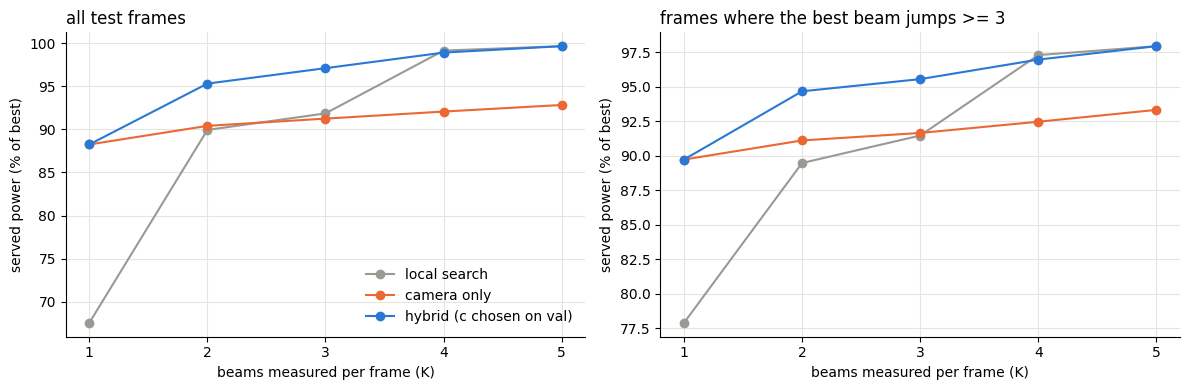


saved in S32/: S6b_report.txt, S6b_results.csv, S6b_budget.png


In [12]:
# ==== S6b: LOCAL SEARCH vs CAMERA vs HYBRID AT THE SAME MEASUREMENT BUDGET (run after S5c; independent of S6)
# needs: torch, numpy, pandas, matplotlib. CPU: about 5-15 minutes.
"""
Every method, in every test drive: one full 64-beam sweep at the first frame (serve the best), then exactly K measured
beams per frame (K = 1 ... 5); the base station serves the strongest measured beam. Overhead per frame includes the
first sweep.
  local search   measure the beams nearest the served one: offsets 0, +d, -d, +2d, -2d, ... (d = direction of the
                 last beam change, +1 at the start; flipped after a frame without change, so with K = 2 it checks
                 both sides in turn), the first K of them. With K = 1 it only re-measures the served beam ("stay"),
                 so it cannot track: the fair low-budget comparison starts at K = 2.
  camera         measure the camera model's K best beams (target finder + beam model from the box, as S5c; no feedback)
  hybrid         the first K - c local-search beams + the camera's best beams not already measured, c camera beams;
                 c (0 ... K) chosen per K on the VALIDATION drives (c = 0 is local search)
Also: frames where the best beam JUMPS (|change| >= 3 beams since the previous frame): does the camera help there?
Metrics on the S2 test sample frames: served = best %, served power % of the best, mean power loss (dB), measured
beams per frame. Camera models are trained on the training drives, chosen on validation, 3 seeds.
Output S<scen>/: S6b_report.txt, S6b_results.csv, S6b_budget.png
"""
import os, sys, argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fn

ap = argparse.ArgumentParser()
ap.add_argument("--work", default=r"C:\Users\abdel\OneDrive\Desktop\ODT")
ap.add_argument("--scen", default="32")
ap.add_argument("--seeds", type=int, default=3)
ap.add_argument("--epochs", type=int, default=150)
ap.add_argument("--past", type=int, default=30)
A = ap.parse_args([])   # notebook: settings are the defaults above
if os.path.isdir(A.work):
    os.chdir(A.work)
D = f"S{A.scen}"
K_LIST = (1, 2, 3, 4, 5)


class Tee:
    def __init__(self, path):
        self.f, self.o = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.o.write(s); self.f.write(s); self.f.flush()

    def flush(self):
        self.o.flush(); self.f.flush()


while hasattr(sys.stdout, "o"):
    sys.stdout = sys.stdout.o
sys.stdout = Tee(os.path.join(D, "S6b_report.txt"))

# ------------------------------------------------------------------ 1. data
def evaluate(scores, beam, power, delta=5, K=3):
    rank = np.argsort(-scores, 1); b = np.asarray(beam); err = rank[:, 0] - b
    Y = [1 - np.mean(np.min(np.minimum(np.abs(rank[:, :k] - b[:, None]) / delta, 1), 1)) for k in range(1, K + 1)]
    return dict(top1=100 * np.mean(err == 0), dba=100 * np.mean(Y))


df = pd.read_csv(os.path.join(D, f"S{A.scen}_frames.csv"))
P = np.nan_to_num(np.load(os.path.join(D, f"S{A.scen}_power.npy")).astype(np.float64), nan=0.0)
Yb = np.load(os.path.join(D, "S5_yolo.npy")); T = np.load(os.path.join(D, "S5_target.npz"))
S = np.load(os.path.join(D, "S2_samples.npz"), allow_pickle=True)
rows, ssplit = S["row"], S["split"].astype(str)
target, found = T["target_idx"], T["target_found"]
N, K, _ = Yb.shape
seq, fsplit, beam = df["seq"].to_numpy(), df["split"].to_numpy(), df["beam"].to_numpy()
use = df["usable"].to_numpy()
X, Yc, W, H, C, CL = (Yb[:, :, j] for j in range(6))
real = C > 0
END = {nm: rows[ssplit == nm, -1] for nm in ("train", "val", "test")}
trf = use & (fsplit == "train")
prev = np.full(N, -1)
for i in range(1, N):
    j = i - 1
    while j >= 0 and seq[j] == seq[i] and not use[j]:
        j -= 1
    prev[i] = j if (j >= 0 and seq[j] == seq[i]) else -1
jump = np.zeros(N, bool); ok = prev >= 0
jump[ok] = np.abs(beam[ok] - beam[prev[ok]]) >= 3
print(f"[1] scored test frames {len(END['test'])} | best beam jumps >= 3 beams since the previous frame: "
      f"{100 * jump[END['test']].mean():.1f} % of them")

# ------------------------------------------------------------------ 2. camera: finder + beam model (as S5c, frame level)
shift = np.ones((N, K)); park = np.zeros((N, K))
for i in range(N):
    if i > 0 and seq[i - 1] == seq[i] and real[i - 1].any():
        shift[i] = np.abs(X[i][:, None] - X[i - 1][real[i - 1]][None]).min(1)
    j0 = i
    while j0 > 0 and seq[j0 - 1] == seq[i] and i - j0 < A.past:
        j0 -= 1
    if j0 < i:
        same = (np.abs(X[i][:, None, None] - X[j0:i][None]) < 0.015) & (np.abs(Yc[i][:, None, None] - Yc[j0:i][None]) < 0.03) & real[j0:i][None]
        park[i] = same.any(2).mean(1)
rank_c = np.argsort(np.argsort(-np.where(real, C, -1), 1), 1) / K
rank_a = np.argsort(np.argsort(-np.where(real, W * H, -1), 1), 1) / K
cls = np.stack([CL == c for c in (2, 3, 5, 7)], 2).astype(np.float32)
FEAT = np.concatenate([np.stack([X, Yc, W, H, np.log(np.maximum(W * H, 1e-5)), C, np.minimum(shift, 0.2) * 5, park,
                                 rank_c, rank_a, np.repeat(real.sum(1, keepdims=True) / K, K, 1)], 2), cls], 2).astype(np.float32)
mu_f, sd_f = FEAT[trf][real[trf]].mean(0), FEAT[trf][real[trf]].std(0) + 1e-6
FEATn = np.where(real[..., None], (FEAT - mu_f) / sd_f, 0).astype(np.float32)


def box_input(frames, pick):
    z = FEATn[frames, np.maximum(pick, 0)][:, :6].copy(); z[pick < 0] = 0
    return np.c_[z, (pick >= 0).astype(np.float32)].astype(np.float32)


def track(S_, mu):
    out = np.full(N, -1); px, ps = None, None
    for i in range(N):
        s = S_[i].copy()
        if px is not None and ps == seq[i]:
            s = s - mu * np.abs(X[i] - px) / 0.05
        s[~real[i]] = -np.inf
        out[i] = int(np.argmax(s)) if real[i].any() else -1
        if out[i] >= 0:
            px = X[i, out[i]]
        ps = seq[i]
    return out


def camera_scores(seed):
    """per-frame 64 beam scores from the camera alone (finder + tracking + beam model); chosen on validation"""
    torch.manual_seed(seed)
    rt = np.flatnonzero(trf & found); rv = np.flatnonzero(use & (fsplit == "val") & found)
    fin = nn.Sequential(nn.Linear(FEAT.shape[2], 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    score = lambda x, m: fin(x).squeeze(-1).masked_fill(~m, -1e9)
    opt = torch.optim.AdamW(fin.parameters(), 3e-3, weight_decay=1e-4)
    xt, mt, yt_ = torch.tensor(FEATn[rt]), torch.tensor(real[rt]), torch.tensor(target[rt])
    xv, mv = torch.tensor(FEATn[rv]), torch.tensor(real[rv]); best = (-1, None)
    for ep in range(300):
        perm = torch.randperm(len(rt))
        for b0 in range(0, len(rt), 256):
            i = perm[b0:b0 + 256]; loss = Fn.cross_entropy(score(xt[i], mt[i]), yt_[i]); opt.zero_grad(); loss.backward(); opt.step()
        if ep % 5 == 4:
            with torch.no_grad():
                acc = (score(xv, mv).argmax(1).numpy() == target[rv]).mean()
            if acc > best[0]:
                best = (acc, {k: v.clone() for k, v in fin.state_dict().items()})
    fin.load_state_dict(best[1])
    with torch.no_grad():
        Ssc = torch.log_softmax(score(torch.tensor(FEATn), torch.tensor(real)), 1).numpy()
    accs = {m: np.mean(track(Ssc, m)[rv] == target[rv]) for m in (0, 0.5, 1, 2, 5)}
    pick = track(Ssc, max(accs, key=accs.get))
    bnet = nn.Sequential(nn.Linear(7, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64))
    opt = torch.optim.AdamW(bnet.parameters(), 3e-3, weight_decay=1e-4)
    tr_fr, vfr = END["train"], END["val"]
    zt, yt = torch.tensor(box_input(tr_fr, target[tr_fr])), torch.tensor(beam[tr_fr]); zv = torch.tensor(box_input(vfr, pick[vfr]))
    bb = (-np.inf, None)
    for ep in range(A.epochs):
        bnet.train(); perm = torch.randperm(len(zt))
        for b0 in range(0, len(zt), 64):
            i = perm[b0:b0 + 64]; loss = Fn.cross_entropy(bnet(zt[i]), yt[i]); opt.zero_grad(); loss.backward(); opt.step()
        bnet.eval()
        with torch.no_grad():
            dv = evaluate(bnet(zv).numpy(), beam[vfr], P[vfr])["dba"]
        if dv > bb[0]:
            bb = (dv, {k: v.clone() for k, v in bnet.state_dict().items()})
    bnet.load_state_dict(bb[1]); bnet.eval()
    with torch.no_grad():
        return bnet(torch.tensor(box_input(np.arange(N), pick))).numpy()


# ------------------------------------------------------------------ 3. the measurement loop (same for every method)
def run(frames_split, Kp, c, cam):
    """c = number of camera beams among the K measured (c = 0: local search, c = K: camera only)"""
    served = np.full(N, -1); probes = []
    for d in np.unique(seq[frames_split]):
        fr = np.flatnonzero((seq == d) & use); sb, dirn = -1, 1
        for i in fr:
            if sb < 0:
                cand = np.arange(64)                                            # first frame: full sweep
            else:
                local = []
                for o in [0] + [s * k for k in range(1, 64) for s in (dirn, -dirn)]:
                    b = sb + o
                    if 0 <= b < 64 and b not in local:
                        local.append(b)
                    if len(local) >= Kp - c:
                        break
                local = local[:Kp - c]
                camb = [b for b in np.argsort(-cam[i]) if b not in local][:c] if c > 0 else []
                cand = np.array(local + list(camb), int)
            nb = int(cand[np.argmax(P[i, cand])])
            if sb >= 0 and nb != sb:
                dirn = 1 if nb > sb else -1          # follow the direction the beam moved
            elif sb >= 0:
                dirn = -dirn                         # no change: check the other side next frame
            sb = nb; served[i] = sb; probes.append(len(cand))
    return served, float(np.mean(probes))


def served_metrics(served, fr, probes):
    pr = P[fr, served[fr]] / np.maximum(P[fr].max(1), 1e-12)
    return dict(served_exact=100 * np.mean(served[fr] == beam[fr]), served_power=100 * np.mean(pr),
                loss_db=float(np.mean(-10 * np.log10(np.maximum(pr, 1e-6)))), probes_per_frame=probes)


# ------------------------------------------------------------------ 4. run
RES = []
vfr, tfr = END["val"], END["test"]
zero = np.zeros((N, 64))
for Kp in K_LIST:
    sv, pr = run(tfr, Kp, 0, zero)
    RES.append(dict(method="local search", K=Kp, c=0, seed=0, **served_metrics(sv, tfr, pr),
                    **{f"jump_{k}": v for k, v in served_metrics(sv, tfr[jump[tfr]], pr).items() if k != "probes_per_frame"}))
for seed in range(A.seeds):
    cam = camera_scores(seed)
    for Kp in K_LIST:
        sv, pr = run(tfr, Kp, Kp, cam)
        RES.append(dict(method="camera only", K=Kp, c=Kp, seed=seed, **served_metrics(sv, tfr, pr),
                        **{f"jump_{k}": v for k, v in served_metrics(sv, tfr[jump[tfr]], pr).items() if k != "probes_per_frame"}))
        vals = {c: served_metrics(run(vfr, Kp, c, cam)[0], vfr, 0)["served_power"] for c in range(Kp + 1)}
        c = max(vals, key=vals.get)
        sv, pr = run(tfr, Kp, c, cam)
        RES.append(dict(method="hybrid (c chosen on val)", K=Kp, c=c, seed=seed, **served_metrics(sv, tfr, pr),
                        **{f"jump_{k}": v for k, v in served_metrics(sv, tfr[jump[tfr]], pr).items() if k != "probes_per_frame"}))
        print(f"  seed {seed} K={Kp}: hybrid uses c = {c} camera beams | served power {RES[-1]['served_power']:.1f} % "
              f"(local search {RES[[r['method'] for r in RES].index('local search') + Kp - 1]['served_power']:.1f} %)")

# ------------------------------------------------------------------ 5. report + figure
R = pd.DataFrame(RES); R.to_csv(os.path.join(D, "S6b_results.csv"), index=False)
print(f"\n[5] TEST DRIVES ({len(tfr)} scored frames; {int(jump[tfr].sum())} with a beam jump >= 3), mean over seeds")
print(f"{'method':26s}{'K':>3s}{'camera beams':>14s}{'beams/frame':>13s}{'served=best %':>15s}{'served power %':>16s}{'loss dB':>9s}"
      f"{'| on jumps: power %':>20s}")
for (mth, Kp), q in R.groupby(["method", "K"], sort=False):
    print(f"{mth:26s}{Kp:3d}{q['c'].mean():14.1f}{q['probes_per_frame'].mean():13.2f}{q['served_exact'].mean():15.1f}"
          f"{q['served_power'].mean():16.1f}{q['loss_db'].mean():9.2f}{q['jump_served_power'].mean():20.1f}")
print("beams/frame includes the one full 64-beam sweep at the start of each drive. 'c' = camera beams among the K.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4)); col = {"local search": "#9a9a94", "camera only": "#eb6834", "hybrid (c chosen on val)": "#2a78d6"}
for mth, q in R.groupby("method", sort=False):
    g = q.groupby("K")[["served_power", "jump_served_power"]].mean()
    ax[0].plot(g.index, g["served_power"], "o-", color=col[mth], label=mth)
    ax[1].plot(g.index, g["jump_served_power"], "o-", color=col[mth], label=mth)
ax[0].set_title("all test frames", loc="left"); ax[1].set_title("frames where the best beam jumps >= 3", loc="left")
for a_ in ax:
    a_.set_xlabel("beams measured per frame (K)"); a_.set_ylabel("served power (% of best)"); a_.set_xticks(K_LIST)
    a_.spines[["top", "right"]].set_visible(False); a_.grid(color="#e6e5e0", lw=0.8)
ax[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(D, "S6b_budget.png"), dpi=140); plt.show()
print(f"\nsaved in {D}/: S6b_report.txt, S6b_results.csv, S6b_budget.png")

while hasattr(sys.stdout, "o"):        # back to normal printing
    sys.stdout = sys.stdout.o

Supervised Models BreakDown

[1] samples train 1849 | val 516 | test 635 | test frames with a beam jump >= 3: 14.2 %

  seed 0: finder picks the GPS-labelled car in 72.4 % of test frames
    box MLP     best epoch 122 | one look top-1 27.6 DBA 65.9 | served power K1 90.0 (c=1) K2 97.4 (c=1) K3 98.5 (c=1) K4 99.1 (c=1) K5 99.6 (c=0)
    box CNN     best epoch  43 | one look top-1 26.5 DBA 64.8 | served power K1 89.3 (c=1) K2 96.7 (c=1) K3 98.3 (c=1) K4 98.8 (c=1) K5 99.6 (c=0)
    box BiLSTM  best epoch  76 | one look top-1 28.3 DBA 66.6 | served power K1 89.3 (c=1) K2 96.3 (c=1) K3 98.3 (c=1) K4 99.2 (c=1) K5 99.6 (c=0)
    box GRU     best epoch 113 | one look top-1 26.5 DBA 65.1 | served power K1 89.6 (c=1) K2 96.2 (c=1) K3 98.4 (c=1) K4 99.1 (c=1) K5 99.6 (c=0)

  seed 1: finder picks the GPS-labelled car in 62.7 % of test frames
    box MLP     best epoch  61 | one look top-1 23.8 DBA 57.8 | served power K1 84.8 (c=1) K2 91.5 (c=1) K3 94.7 (c=1) K4 95.7 (c=1) K5 95.9 (c=2)
    box CNN     best epoch  47 | one 

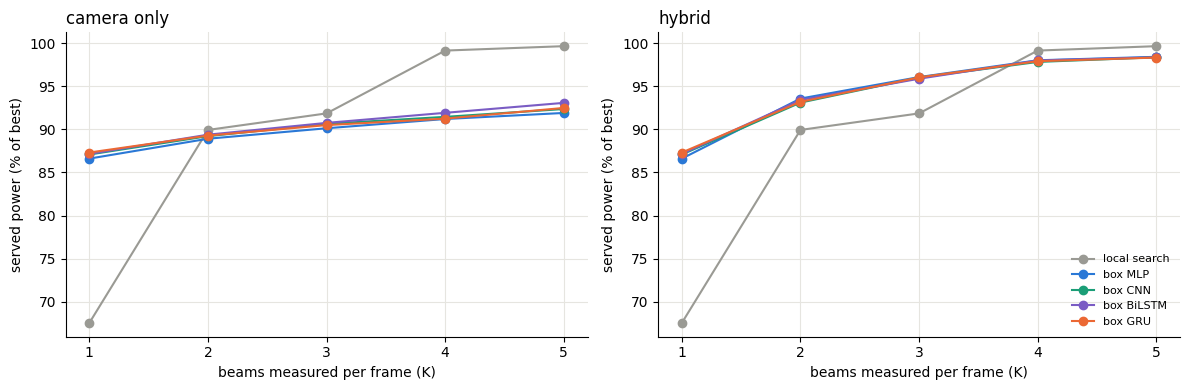


saved in S32/: S6c_report.txt, S6c_results.csv, S6c_budget.png


In [1]:
# ==== S6c: ALL SUPERVISED BASELINES ON THE CAMERA BOX SEQUENCE, EVALUATED 3 WAYS (run after S5c)
# needs: torch, numpy, pandas, matplotlib. CPU: about 15-30 minutes.
"""
Camera input for every model: the target finder (as S5c, trained with the S5b GPS labels on the training drives;
no GPS at test time) picks the test car's box in each frame; per frame the model sees
[x, y, w, h, log area, confidence, box flag] of the picked box, for the last 5 frames (t-4 ... t).
Supervised beam models (all trained on the GPS-labelled boxes of the training samples, cross-entropy; best epoch =
highest validation DBA using the finder's picks):
  box MLP       frame t only
  box CNN       1-D convolution over the 5 frames
  box BiLSTM    bidirectional LSTM over the 5-frame window (all frames are past or current: still online)
  box GRU       GRU over the 5 frames
Each model is reported three ways on the test drives:
  1 one look       top-1 / top-3 / power % / DBA on the S2 test samples (no measuring)
  2 camera only    closed loop: measure the model's K best beams, serve the strongest (K = 1 ... 5)
  3 hybrid         closed loop: K - c local-search beams + the model's c best other beams, c chosen on validation
Closed loop as S6b: one full sweep at the start of each drive, then K measured beams per frame. Local search shown
for reference. 3 seeds (finder + models retrained per seed).
Output S<scen>/: S6c_report.txt, S6c_results.csv, S6c_budget.png
"""
import os, sys, argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fn

ap = argparse.ArgumentParser()
ap.add_argument("--work", default=r"C:\Users\abdel\OneDrive\Desktop\ODT")
ap.add_argument("--scen", default="32")
ap.add_argument("--seeds", type=int, default=3)
ap.add_argument("--epochs", type=int, default=150)
ap.add_argument("--past", type=int, default=30)
A = ap.parse_args([])   # notebook: settings are the defaults above
if os.path.isdir(A.work):
    os.chdir(A.work)
D = f"S{A.scen}"
K_LIST = (1, 2, 3, 4, 5)


class Tee:
    def __init__(self, path):
        self.f, self.o = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.o.write(s); self.f.write(s); self.f.flush()

    def flush(self):
        self.o.flush(); self.f.flush()


while hasattr(sys.stdout, "o"):
    sys.stdout = sys.stdout.o
sys.stdout = Tee(os.path.join(D, "S6c_report.txt"))

# ------------------------------------------------------------------ 1. data
def evaluate(scores, beam, power, delta=5, K=3):
    rank = np.argsort(-scores, 1); b = np.asarray(beam); err = rank[:, 0] - b
    Y = [1 - np.mean(np.min(np.minimum(np.abs(rank[:, :k] - b[:, None]) / delta, 1), 1)) for k in range(1, K + 1)]
    return dict(top1=100 * np.mean(err == 0), top3=100 * np.mean((rank[:, :3] == b[:, None]).any(1)),
                power=100 * np.mean(power[np.arange(len(b)), rank[:, 0]] / np.maximum(power.max(1), 1e-12)),
                dba=100 * np.mean(Y))


df = pd.read_csv(os.path.join(D, f"S{A.scen}_frames.csv"))
P = np.nan_to_num(np.load(os.path.join(D, f"S{A.scen}_power.npy")).astype(np.float64), nan=0.0)
Yb = np.load(os.path.join(D, "S5_yolo.npy")); T = np.load(os.path.join(D, "S5_target.npz"))
S = np.load(os.path.join(D, "S2_samples.npz"), allow_pickle=True)
rows, ssplit = S["row"], S["split"].astype(str)
target, found = T["target_idx"], T["target_found"]
N, K, _ = Yb.shape
seq, fsplit, beam = df["seq"].to_numpy(), df["split"].to_numpy(), df["beam"].to_numpy()
use = df["usable"].to_numpy()
X, Yc, W, H, C, CL = (Yb[:, :, j] for j in range(6))
real = C > 0
idx = {nm: np.flatnonzero(ssplit == nm) for nm in ("train", "val", "test")}
END = {nm: rows[idx[nm], -1] for nm in idx}
trf = use & (fsplit == "train")
WIN = np.zeros((N, 5), int)                                                      # last 5 usable frames up to i (causal)
for d in np.unique(seq):
    fr = np.flatnonzero((seq == d) & use)
    for j, i in enumerate(fr):
        w = fr[max(0, j - 4):j + 1]; WIN[i] = np.r_[np.full(5 - len(w), w[0]), w]
prev = np.full(N, -1)
for i in range(1, N):
    j = i - 1
    while j >= 0 and seq[j] == seq[i] and not use[j]:
        j -= 1
    prev[i] = j if (j >= 0 and seq[j] == seq[i]) else -1
jump = np.zeros(N, bool); ok = prev >= 0; jump[ok] = np.abs(beam[ok] - beam[prev[ok]]) >= 3
print(f"[1] samples train {len(idx['train'])} | val {len(idx['val'])} | test {len(idx['test'])} | "
      f"test frames with a beam jump >= 3: {100 * jump[END['test']].mean():.1f} %")

# ------------------------------------------------------------------ 2. finder (as S5c)
shift = np.ones((N, K)); park = np.zeros((N, K))
for i in range(N):
    if i > 0 and seq[i - 1] == seq[i] and real[i - 1].any():
        shift[i] = np.abs(X[i][:, None] - X[i - 1][real[i - 1]][None]).min(1)
    j0 = i
    while j0 > 0 and seq[j0 - 1] == seq[i] and i - j0 < A.past:
        j0 -= 1
    if j0 < i:
        same = (np.abs(X[i][:, None, None] - X[j0:i][None]) < 0.015) & (np.abs(Yc[i][:, None, None] - Yc[j0:i][None]) < 0.03) & real[j0:i][None]
        park[i] = same.any(2).mean(1)
rank_c = np.argsort(np.argsort(-np.where(real, C, -1), 1), 1) / K
rank_a = np.argsort(np.argsort(-np.where(real, W * H, -1), 1), 1) / K
cls = np.stack([CL == c for c in (2, 3, 5, 7)], 2).astype(np.float32)
FEAT = np.concatenate([np.stack([X, Yc, W, H, np.log(np.maximum(W * H, 1e-5)), C, np.minimum(shift, 0.2) * 5, park,
                                 rank_c, rank_a, np.repeat(real.sum(1, keepdims=True) / K, K, 1)], 2), cls], 2).astype(np.float32)
mu_f, sd_f = FEAT[trf][real[trf]].mean(0), FEAT[trf][real[trf]].std(0) + 1e-6
FEATn = np.where(real[..., None], (FEAT - mu_f) / sd_f, 0).astype(np.float32)


def box_input(pick):
    z = FEATn[np.arange(N), np.maximum(pick, 0)][:, :6].copy(); z[pick < 0] = 0
    return np.c_[z, (pick >= 0).astype(np.float32)].astype(np.float32)


def track(S_, mu):
    out = np.full(N, -1); px, ps = None, None
    for i in range(N):
        s = S_[i].copy()
        if px is not None and ps == seq[i]:
            s = s - mu * np.abs(X[i] - px) / 0.05
        s[~real[i]] = -np.inf
        out[i] = int(np.argmax(s)) if real[i].any() else -1
        if out[i] >= 0:
            px = X[i, out[i]]
        ps = seq[i]
    return out


def finder_picks(seed):
    torch.manual_seed(seed)
    rt = np.flatnonzero(trf & found); rv = np.flatnonzero(use & (fsplit == "val") & found)
    fin = nn.Sequential(nn.Linear(FEAT.shape[2], 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    score = lambda x, m: fin(x).squeeze(-1).masked_fill(~m, -1e9)
    opt = torch.optim.AdamW(fin.parameters(), 3e-3, weight_decay=1e-4)
    xt, mt, yt_ = torch.tensor(FEATn[rt]), torch.tensor(real[rt]), torch.tensor(target[rt])
    xv, mv = torch.tensor(FEATn[rv]), torch.tensor(real[rv]); best = (-1, None)
    for ep in range(300):
        perm = torch.randperm(len(rt))
        for b0 in range(0, len(rt), 256):
            i = perm[b0:b0 + 256]; loss = Fn.cross_entropy(score(xt[i], mt[i]), yt_[i]); opt.zero_grad(); loss.backward(); opt.step()
        if ep % 5 == 4:
            with torch.no_grad():
                acc = (score(xv, mv).argmax(1).numpy() == target[rv]).mean()
            if acc > best[0]:
                best = (acc, {k: v.clone() for k, v in fin.state_dict().items()})
    fin.load_state_dict(best[1])
    with torch.no_grad():
        Ssc = torch.log_softmax(score(torch.tensor(FEATn), torch.tensor(real)), 1).numpy()
    accs = {m: np.mean(track(Ssc, m)[rv] == target[rv]) for m in (0, 0.5, 1, 2, 5)}
    return track(Ssc, max(accs, key=accs.get))


# ------------------------------------------------------------------ 3. the four supervised models
class BoxMLP(nn.Module):
    def __init__(self, d):
        super().__init__(); self.f = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 64))

    def forward(self, x):
        return self.f(x[:, -1])


class BoxCNN(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.c1, self.c2 = nn.Conv1d(d, 64, 3, padding=1), nn.Conv1d(64, 64, 3, padding=1)
        self.f = nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 64))

    def forward(self, x):                                   # x (B, 5, d)
        h = Fn.relu(self.c2(Fn.relu(self.c1(x.transpose(1, 2)))))
        return self.f(torch.cat([h[:, :, -1], h.mean(2)], 1))


class BoxBiLSTM(nn.Module):
    def __init__(self, d):
        super().__init__(); self.rnn = nn.LSTM(d, 64, batch_first=True, bidirectional=True); self.fc = nn.Linear(128, 64)

    def forward(self, x):
        _, (hn, _) = self.rnn(x)
        return self.fc(torch.cat([hn[0], hn[1]], 1))


class BoxGRU(nn.Module):
    def __init__(self, d):
        super().__init__(); self.gru = nn.GRU(d, 64, num_layers=2, batch_first=True, dropout=0.1); self.fc = nn.Linear(64, 64)

    def forward(self, x):
        o, _ = self.gru(x)
        return self.fc(o[:, -1])


MODELS = {"box MLP": BoxMLP, "box CNN": BoxCNN, "box BiLSTM": BoxBiLSTM, "box GRU": BoxGRU}


def train_model(Model, Z_gps, Z_pipe, seed):
    torch.manual_seed(seed)
    m = Model(Z_gps.shape[1]); opt = torch.optim.AdamW(m.parameters(), 3e-3, weight_decay=1e-4)
    xs = torch.tensor(Z_gps[rows[idx["train"]]]); ys = torch.tensor(beam[END["train"]])
    xv = torch.tensor(Z_pipe[rows[idx["val"]]]); best = (-np.inf, None, 0)
    for ep in range(A.epochs):
        m.train(); perm = torch.randperm(len(xs))
        for b0 in range(0, len(xs), 64):
            i = perm[b0:b0 + 64]; loss = Fn.cross_entropy(m(xs[i]), ys[i]); opt.zero_grad(); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad():
            dv = evaluate(m(xv).numpy(), beam[END["val"]], P[END["val"]])["dba"]
        if dv > best[0]:
            best = (dv, {k: v.clone() for k, v in m.state_dict().items()}, ep + 1)
    m.load_state_dict(best[1]); m.eval()
    return m, best[2]


# ------------------------------------------------------------------ 4. closed loop (as S6b)
def run(frames_split, Kp, c, cam):
    served = np.full(N, -1); probes = []
    for d in np.unique(seq[frames_split]):
        fr = np.flatnonzero((seq == d) & use); sb, dirn = -1, 1
        for i in fr:
            if sb < 0:
                cand = np.arange(64)
            else:
                local = []
                for o in [0] + [s * k for k in range(1, 64) for s in (dirn, -dirn)]:
                    b = sb + o
                    if 0 <= b < 64 and b not in local:
                        local.append(b)
                    if len(local) >= Kp - c:
                        break
                local = local[:Kp - c]
                camb = [b for b in np.argsort(-cam[i]) if b not in local][:c] if c > 0 else []
                cand = np.array(local + list(camb), int)
            nb = int(cand[np.argmax(P[i, cand])])
            if sb >= 0 and nb != sb:
                dirn = 1 if nb > sb else -1
            elif sb >= 0:
                dirn = -dirn
            sb = nb; served[i] = sb; probes.append(len(cand))
    return served, float(np.mean(probes))


def served_power(served, fr):
    return 100 * np.mean(P[fr, served[fr]] / np.maximum(P[fr].max(1), 1e-12))


def served_metrics(served, fr):
    pr = P[fr, served[fr]] / np.maximum(P[fr].max(1), 1e-12)
    return dict(served_exact=100 * np.mean(served[fr] == beam[fr]), served_power=100 * np.mean(pr),
                loss_db=float(np.mean(-10 * np.log10(np.maximum(pr, 1e-6)))),
                jump_served_power=served_power(served, fr[jump[fr]]))


# ------------------------------------------------------------------ 5. run everything
RES = []
vfr, tfr = END["val"], END["test"]
for Kp in K_LIST:
    sv, pr = run(tfr, Kp, 0, None)
    RES.append(dict(model="local search (no camera)", mode="closed loop", K=Kp, c=0, seed=0, beams_per_frame=pr, **served_metrics(sv, tfr)))
for seed in range(A.seeds):
    pick = finder_picks(seed)
    tf = tfr[found[tfr]]
    print(f"\n  seed {seed}: finder picks the GPS-labelled car in {100 * np.mean(pick[tf] == target[tf]):.1f} % of test frames")
    Z_gps, Z_pipe = box_input(target), box_input(pick)
    for name, Model in MODELS.items():
        m, be = train_model(Model, Z_gps, Z_pipe, seed)
        with torch.no_grad():
            one = evaluate(m(torch.tensor(Z_pipe[rows[idx["test"]]])).numpy(), beam[tfr], P[tfr])
            cam = m(torch.tensor(Z_pipe[WIN])).numpy()                          # scores for every frame (causal window)
        RES.append(dict(model=name, mode="1 one look", K=0, c=0, seed=seed, best_epoch=be, **one))
        line = f"    {name:11s} best epoch {be:3d} | one look top-1 {one['top1']:.1f} DBA {one['dba']:.1f} | served power"
        for Kp in K_LIST:
            sv, pr = run(tfr, Kp, Kp, cam)
            RES.append(dict(model=name, mode="2 camera only", K=Kp, c=Kp, seed=seed, beams_per_frame=pr, **served_metrics(sv, tfr)))
            vals = {c: served_power(run(vfr, Kp, c, cam)[0], vfr) for c in range(Kp + 1)}
            c = max(vals, key=vals.get); sv, pr = run(tfr, Kp, c, cam)
            RES.append(dict(model=name, mode="3 hybrid", K=Kp, c=c, seed=seed, beams_per_frame=pr, **served_metrics(sv, tfr)))
            line += f" K{Kp} {RES[-1]['served_power']:.1f} (c={c})"
        print(line)

# ------------------------------------------------------------------ 6. report + figure
R = pd.DataFrame(RES); R.to_csv(os.path.join(D, "S6c_results.csv"), index=False)
print(f"\n[1] ONE LOOK (no measuring), test samples, mean +- std over {A.seeds} seeds")
print(f"{'model':14s}{'top-1 %':>14s}{'top-3 %':>14s}{'power %':>14s}{'DBA %':>14s}")
for nm in MODELS:
    q = R[(R["model"] == nm) & (R["mode"] == "1 one look")]
    print(f"{nm:14s}" + "".join(f"{q[c].mean():8.1f} +-{q[c].std(ddof=0):3.1f}" for c in ("top1", "top3", "power", "dba")))
for mode in ("2 camera only", "3 hybrid"):
    print(f"\n[{mode[0]}] CLOSED LOOP, {mode[2:].upper()}: served power % of the best beam (mean +- std over seeds)")
    print(f"{'model':26s}" + "".join(f"{'K=' + str(k):>14s}" for k in K_LIST) + f"{'jumps, K=3':>14s}")
    q = R[R["model"] == "local search (no camera)"]
    print(f"{'local search (no camera)':26s}" + "".join(f"{q[q['K'] == k]['served_power'].mean():14.1f}" for k in K_LIST)
          + f"{q[q['K'] == 3]['jump_served_power'].mean():14.1f}")
    for nm in MODELS:
        q = R[(R["model"] == nm) & (R["mode"] == mode)]
        print(f"{nm:26s}" + "".join(f"{q[q['K'] == k]['served_power'].mean():8.1f} +-{q[q['K'] == k]['served_power'].std(ddof=0):3.1f}" for k in K_LIST)
              + f"{q[q['K'] == 3]['jump_served_power'].mean():14.1f}")
print("\nK = beams measured per frame after one full sweep at the start of each drive. Hybrid: c of the K beams come from the model.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4)); pal = dict(zip(MODELS, ["#2a78d6", "#1b9e77", "#7a5cc4", "#eb6834"]))
q = R[R["model"] == "local search (no camera)"].groupby("K")["served_power"].mean()
for a_, mode in zip(ax, ("2 camera only", "3 hybrid")):
    a_.plot(q.index, q.values, "o-", color="#9a9a94", label="local search")
    for nm in MODELS:
        g = R[(R["model"] == nm) & (R["mode"] == mode)].groupby("K")["served_power"].mean()
        a_.plot(g.index, g.values, "o-", color=pal[nm], label=nm)
    a_.set_title(mode[2:], loc="left"); a_.set_xlabel("beams measured per frame (K)"); a_.set_ylabel("served power (% of best)")
    a_.set_xticks(K_LIST); a_.spines[["top", "right"]].set_visible(False); a_.grid(color="#e6e5e0", lw=0.8)
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(D, "S6c_budget.png"), dpi=140); plt.show()
print(f"\nsaved in {D}/: S6c_report.txt, S6c_results.csv, S6c_budget.png")

while hasattr(sys.stdout, "o"):        # back to normal printing
    sys.stdout = sys.stdout.o